# Trabalho 2 - Aprendizagem de Máquina Probabilística
## TIAGO OLIVEIRA LIMA -564988

In [22]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)
BASE = Path.cwd()

def gaussian_posterior(Phi, y, alpha, beta):
    """p(w|D) para p(w)=N(0, alpha^-1 I) e y|w=N(Phi w, beta^-1 I)."""
    precision = alpha * np.eye(Phi.shape[1]) + beta * Phi.T @ Phi
    covariance = np.linalg.inv(precision)
    mean = beta * covariance @ Phi.T @ y
    return mean, covariance

def predictive_gaussian(Phi_star, mean_w, covariance_w, beta):
    mean = Phi_star @ mean_w
    variance = 1 / beta + np.sum((Phi_star @ covariance_w) * Phi_star, axis=1)
    return mean, np.sqrt(variance)

def plot_regression(x, y, x_grid, mean, sigma, title):
    fig, ax = plt.subplots(figsize=(8, 4.6))
    ax.scatter(x, y, color='navy', label='Dados', zorder=3)
    ax.plot(x_grid, mean, color='blue', lw=2.2, label='Média preditiva')
    ax.fill_between(x_grid, mean - 2*sigma, mean + 2*sigma, color='blue', alpha=.18, label='±2σ')
    ax.set(title=title, xlabel='x', ylabel='y')
    ax.grid(alpha=.25)
    ax.legend()
    plt.show()

## 1. Regressão linear Bayesiana

Usa-se \(y=w_0+w_1x+\varepsilon\), com prior isotrópico \(w\sim\mathcal N(0,\alpha^{-1}I)\) e ruído \(\varepsilon\sim\mathcal N(0,\beta^{-1})\).

In [23]:
linear = np.loadtxt(BASE / 'linear_regression_data.csv', delimiter=',')
x_lin, y_lin = linear[:, 0], linear[:, 1]
Phi_lin = np.column_stack([np.ones_like(x_lin), x_lin])
xg_lin = np.linspace(x_lin.min() - .1, x_lin.max() + .1, 300)
Phi_g_lin = np.column_stack([np.ones_like(xg_lin), xg_lin])

alpha_lin = 2.0                
sigma_noise_lin = 0.20
beta_lin = 1 / sigma_noise_lin**2
m0_lin = np.zeros(2)
S0_lin = np.eye(2) / alpha_lin

prior_mean_lin, prior_sigma_lin = predictive_gaussian(Phi_g_lin, m0_lin, S0_lin, beta_lin)
m_lin, S_lin = gaussian_posterior(Phi_lin, y_lin, alpha_lin, beta_lin)
post_mean_lin, post_sigma_lin = predictive_gaussian(Phi_g_lin, m_lin, S_lin, beta_lin)
print('Média posterior [intercepto, inclinação]:', m_lin)
print('Desvio-padrão posterior dos pesos:', np.sqrt(np.diag(S_lin)))

Média posterior [intercepto, inclinação]: [-0.2396  0.5158]
Desvio-padrão posterior dos pesos: [0.0642 0.1423]


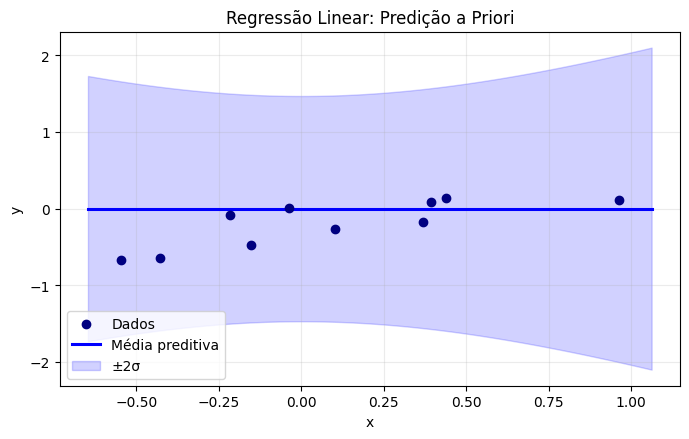

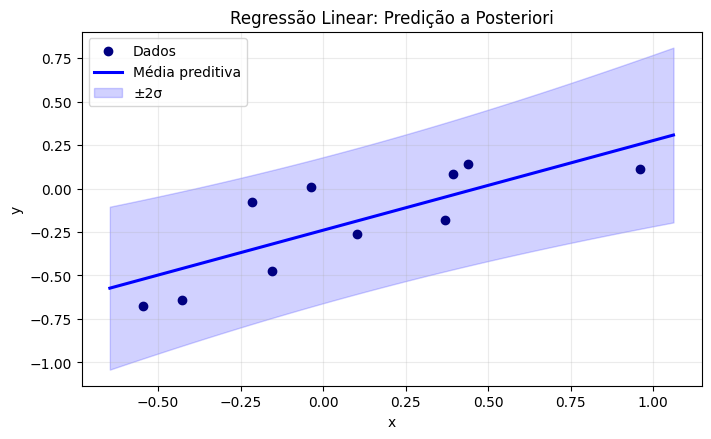

In [24]:
plot_regression(x_lin, y_lin, xg_lin, prior_mean_lin, prior_sigma_lin,
                'Regressão Linear: Predição a Priori')
plot_regression(x_lin, y_lin, xg_lin, post_mean_lin, post_sigma_lin,
                'Regressão Linear: Predição a Posteriori')

## 2. Regressão polinomial Bayesiana (grau 5)

A matriz de projeto contém \([1,x,x^2,\ldots,x^5]\). A inferência é a mesma da regressão linear, pois o modelo ainda é linear nos pesos.

In [25]:
def polynomial_design(x, degree=5):
    return np.column_stack([x**power for power in range(degree + 1)])

poly = np.loadtxt(BASE / 'polynomial_regression_data.csv', delimiter=',')
x_poly, y_poly = poly[:, 0], poly[:, 1]
Phi_poly = polynomial_design(x_poly, degree=5)
xg_poly = np.linspace(x_poly.min() - .03, x_poly.max() + .03, 400)
Phi_g_poly = polynomial_design(xg_poly, degree=5)

alpha_poly = 5.0
sigma_noise_poly = 0.20
beta_poly = 1 / sigma_noise_poly**2
m0_poly = np.zeros(6)
S0_poly = np.eye(6) / alpha_poly

prior_mean_poly, prior_sigma_poly = predictive_gaussian(Phi_g_poly, m0_poly, S0_poly, beta_poly)
m_poly, S_poly = gaussian_posterior(Phi_poly, y_poly, alpha_poly, beta_poly)
post_mean_poly, post_sigma_poly = predictive_gaussian(Phi_g_poly, m_poly, S_poly, beta_poly)
print('Média posterior dos pesos:', m_poly)
print('Desvio-padrão posterior dos pesos:', np.sqrt(np.diag(S_poly)))

Média posterior dos pesos: [ 0.9613 -1.2772 -1.0451 -0.348   0.2997  0.7966]
Desvio-padrão posterior dos pesos: [0.1533 0.3594 0.3862 0.3957 0.387  0.37  ]


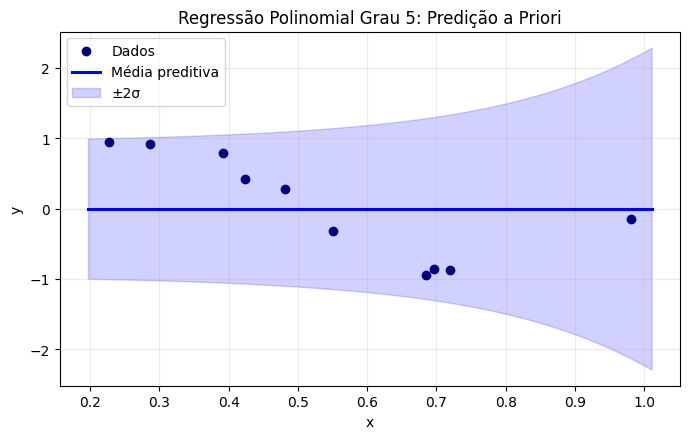

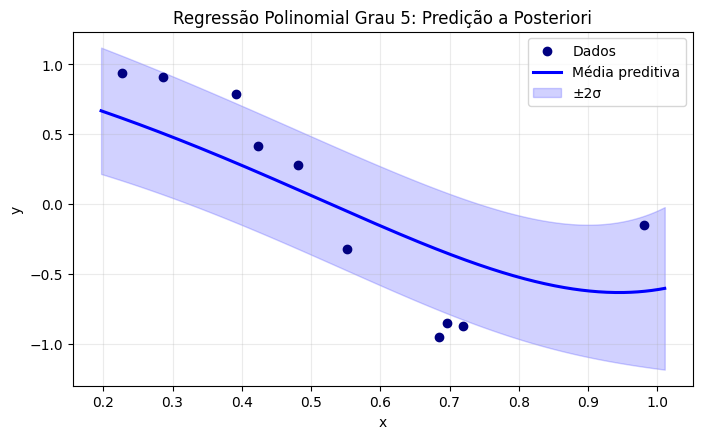

In [26]:
plot_regression(x_poly, y_poly, xg_poly, prior_mean_poly, prior_sigma_poly,
                'Regressão Polinomial Grau 5: Predição a Priori')
plot_regression(x_poly, y_poly, xg_poly, post_mean_poly, post_sigma_poly,
                'Regressão Polinomial Grau 5: Predição a Posteriori')

## 3. Regressão logística Bayesiana

Com \(p(t=1|x,w)=\sigma(w^T\phi(x))\) e prior \(w\sim\mathcal N(0,\alpha^{-1}I)\), o MAP é obtido pelo IRLS. A gaussiana de Laplace \(\mathcal N(w_{MAP}, A^{-1})\), onde \(A=\alpha I+\Phi^TR\Phi\), permite integrar aproximadamente a incerteza nos pesos por Monte Carlo.

In [27]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def logistic_map_irls(Phi, target, alpha, max_iter=100, tolerance=1e-9):
    """Newton-Raphson/IRLS para maximizar log p(w|D)."""
    w = np.zeros(Phi.shape[1])
    for iteration in range(max_iter):
        p = sigmoid(Phi @ w)
        r = np.clip(p * (1 - p), 1e-10, None)
        # A é o negativo da Hessiana do log-posterior.
        A = alpha * np.eye(Phi.shape[1]) + Phi.T @ (r[:, None] * Phi)
        gradient = Phi.T @ (target - p) - alpha * w
        step = np.linalg.solve(A, gradient)
        w = w + step
        if np.linalg.norm(step) < tolerance:
            break
    p = sigmoid(Phi @ w)
    r = np.clip(p * (1 - p), 1e-10, None)
    A = alpha * np.eye(Phi.shape[1]) + Phi.T @ (r[:, None] * Phi)
    return w, np.linalg.inv(A), iteration + 1

logistic = np.loadtxt(BASE / 'logistic_regression_data.csv', delimiter=',')
x1, x2, target = logistic[:, 0], logistic[:, 1], logistic[:, 2].astype(int)
Phi_log = np.column_stack([np.ones_like(x1), x1, x2])
alpha_log = 1.0
w_map, S_map, n_iter = logistic_map_irls(Phi_log, target, alpha_log)
print(f'IRLS convergiu em {n_iter} iterações.')
print('w_MAP [intercepto, peso x1, peso x2]:', w_map)
print('Desvio-padrão de Laplace:', np.sqrt(np.diag(S_map)))

IRLS convergiu em 8 iterações.
w_MAP [intercepto, peso x1, peso x2]: [ 0.5153 -2.8128  1.4486]
Desvio-padrão de Laplace: [0.4099 0.5375 0.569 ]


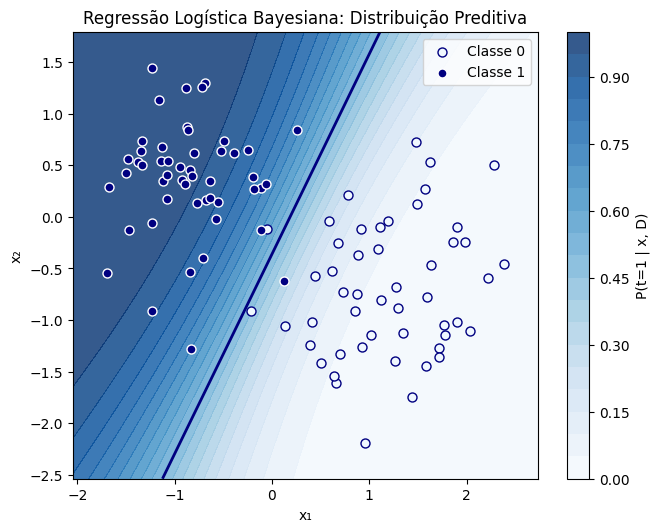

In [28]:
# Monte Carlo: w^(s) ~ N(w_MAP, S_MAP); P(t*=1|x*,D) é a média das probabilidades.
n_samples = 10_000
L = np.linalg.cholesky(S_map)
weight_samples = w_map + rng.standard_normal((n_samples, 3)) @ L.T

pad = .35
g1 = np.linspace(x1.min() - pad, x1.max() + pad, 220)
g2 = np.linspace(x2.min() - pad, x2.max() + pad, 220)
G1, G2 = np.meshgrid(g1, g2)
Phi_grid = np.column_stack([np.ones(G1.size), G1.ravel(), G2.ravel()])
# Processamento em lotes evita criar uma matriz 10.000 x 48.400 de uma vez.
probability = np.empty(Phi_grid.shape[0])
for start in range(0, Phi_grid.shape[0], 1000):
    stop = min(start + 1000, Phi_grid.shape[0])
    probability[start:stop] = sigmoid(Phi_grid[start:stop] @ weight_samples.T).mean(axis=1)
P = probability.reshape(G1.shape)

fig, ax = plt.subplots(figsize=(7.5, 5.8))
heat = ax.contourf(G1, G2, P, levels=np.linspace(0, 1, 21), cmap='Blues', alpha=.82)
ax.contour(G1, G2, P, levels=[.5], colors='navy', linewidths=2)
ax.scatter(x1[target == 0], x2[target == 0], color='aliceblue', edgecolor='navy', label='Classe 0', s=42)
ax.scatter(x1[target == 1], x2[target == 1], color='navy', edgecolor='white', label='Classe 1', s=42)
fig.colorbar(heat, ax=ax, label='P(t=1 | x, D)')
ax.set(title='Regressão Logística Bayesiana: Distribuição Preditiva', xlabel='x₁', ylabel='x₂')
ax.legend()
plt.show()